# Mutascape, end to end

Build a CreiLOV oracle from a wild type and twenty measured single mutants.
Compare it against the 165,428-variant combinatorial landscape Chen et al.
measured over 15 positions.

Every number below is computed here.

## Before you start

Download the measured landscapes once.

```bash
just benchmark-data
```

The data is written to `.mutascape/benchmark-data/`.

## 1. Configure

The only cell you edit to change protein.

In [1]:
TARGET = "CreiLOV_fluorescence"
SEED = 20260909
COUPLING = 0.1  # frozen default, validated across the benchmark corpora
BUDGET = 96  # queries a search method may spend
TRIALS = 5  # search seeds per method and arm

BENCHMARK_ROOT = "../.mutascape/benchmark-data"

# Other targets, all one-line swaps.
#
#   CombinGym : GB1_binding, CR9114_H1_binding, CR6261_H1_binding,
#               eqFP611_red, eqFP611_blue, HIV1_activity, RhlA_RLs
#   SSMuLA    : GB1, TrpB4, TEV, DHFR, ParD3, T7, TrpB3A

In [2]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kendalltau, spearmanr

from mutascape import from_dms, load_oracle, run_campaign
from mutascape.benchmarks import (
    classifier_two_sample_test,
    completion_fidelity_features,
    load_combingym_landscapes,
    load_ssmula_landscapes,
    mutation_order_split,
)
from mutascape.benchmarks.generators import (
    dms_pairwise_readout_tensor,
    nk_tensor,
    potts_tensor,
)
from mutascape.benchmarks.library import SearchSpace
from mutascape.benchmarks.methods import METHODS, make_features, run_method
from mutascape.benchmarks.topology import additive_tensor, measured_tensor, supported_cube
from mutascape.validation.fourier import walsh_decompose
from mutascape.validation.metrics import local_optima_from_tensor

pd.set_option("display.width", 130)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": 0.25})

ROOT = Path(BENCHMARK_ROOT)


def corpus() -> dict:
    """Every measured landscape on disk, keyed by name."""
    found = load_combingym_landscapes(ROOT / "combingym", strict=False)
    found += load_ssmula_landscapes(ROOT / "ssmula", strict=False)
    if not found:
        raise FileNotFoundError(
            f"no landscapes under {ROOT.resolve()}. "
            "Run scripts/fetch_benchmark_data.py --combingym --ssmula first."
        )
    return {d.name: d for d in found}


LANDSCAPES = corpus()
dataset = LANDSCAPES[TARGET]
print(f"{dataset.name}   protein {dataset.protein}   phenotype {dataset.spec.phenotype}")
print(f"{dataset.n_variants:,} measured genotypes over {len(dataset.mutable_positions)} positions")
print(f"positions {dataset.mutable_positions}")
print(f"source    {dataset.spec.source_url}")

/Users/tomhill/Uni/research-project/mutascape/.venv/lib/python3.14/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


CreiLOV_fluorescence   protein CreiLOV   phenotype fluorescence
165,428 measured genotypes over 15 positions
positions (3, 4, 5, 7, 29, 34, 47, 60, 61, 92, 96, 98, 107, 109, 113)
source    https://github.com/sitonglab/CombinGym


## 2. Split the measured landscape

Mutascape reads the wild type and the single mutants. Depth two and above is
held out as the answer key.

In [3]:
split = mutation_order_split(dataset.variants, max_train_depth=1)
sequence = dataset.wild_type_sequence
wild_type_fitness = float(split.train.loc[split.train.depth == 0, "fitness"].iloc[0])

print(f"visible to mutascape : {len(split.train):>7,}  (wild type and singles)")
print(f"held out             : {len(split.test):>7,}  (depth 2 and above)")
print(f"wild-type assay value: {wild_type_fitness:.4f}")

dms = pd.DataFrame(
    [
        {
            "position": position,
            "wildtype": sequence[position - 1],
            "mutant": residue,
            "fitness": fitness - wild_type_fitness,
        }
        for mutations, fitness in split.train.loc[
            split.train.depth == 1, ["mutations", "fitness"]
        ].itertuples(index=False, name=None)
        for position, residue in mutations.items()
    ]
)
dms.sort_values("fitness", ascending=False).head(8)

visible to mutascape :      21  (wild type and singles)
held out             : 165,407  (depth 2 and above)
wild-type assay value: 4.0232


,position,wildtype,mutant,fitness
0,7,T,S,0.116179
5,34,G,T,0.085563
1,5,R,D,0.085101
6,29,A,H,0.084304
2,7,T,H,0.078612
7,61,D,Q,0.077788
17,107,V,M,0.070544
8,98,R,D,0.048955


Fitness is relative to wild type. The measured tensor is recentred the same way.

CreiLOV supplies twenty singles across fifteen positions. From that mutascape
must produce a surface over the whole cube. Every limitation reported below
follows from this input.

## 3. Build the oracle

`from_dms` conditions a fitted prior on your measurements. `draw` fixes one
landscape. The result is subscriptable.

In [4]:
generator = from_dms(dms, wt_sequence=sequence)
oracle = generator.draw(SEED)
oracle

Oracle(generator="dms-pairwise-v1", seed=20260909, positions=15, substitutions=20, maximum_depth=None)

In [5]:
top = dms.sort_values("fitness", ascending=False).head(4)
variant = "+".join(f"{r.wildtype}{r.position}{r.mutant}" for r in top.itertuples())
single = f"{top.wildtype.iloc[0]}{top.position.iloc[0]}{top.mutant.iloc[0]}"

print(f"{variant}  ->  {oracle[variant]:+.4f}")
print(f"as a dict     ->  {oracle.evaluate({top.position.iloc[0]: top.mutant.iloc[0]}):+.4f}")
print()
print(oracle.score_many([variant, single]))

T7S+G34T+R5D+A29H  ->  +0.2023
as a dict     ->  +0.1162

R5D+T7S+A29H+G34T    0.202261
T7S                  0.116179
Name: fitness, dtype: float64


## 4. Oracle guarantees

Four properties separate this from a random function generator.

In [6]:
singles = split.train.loc[split.train.depth == 1]
predicted = oracle.evaluate_batch(singles.mutations.tolist())
observed = singles.fitness.to_numpy() - wild_type_fitness
error = np.abs(predicted - observed).max()

checks = {
    "wild type is exactly zero": oracle.evaluate({}) == 0.0,
    "measured singles are exact": error < 1e-12,
    "a repeated query never moves": oracle[variant] == oracle[variant],
    "held-out depths are answerable": np.isfinite(
        oracle.evaluate_batch(split.test.mutations.head(50).tolist())
    ).all(),
}
for label, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}  {label}")
print(f"\nlargest single-mutant error over {len(singles):,} measurements: {error:.2e}")

PASS  wild type is exactly zero
PASS  measured singles are exact
PASS  a repeated query never moves
PASS  held-out depths are answerable

largest single-mutant error over 20 measurements: 0.00e+00


### Provenance

`provenance` returns the source of any value. Measured values are returned
unmodified.

In [7]:
probe = [{}, singles.mutations.iloc[0], *split.test.mutations.head(3).tolist()]
for mutations in probe:
    label = "+".join(f"{sequence[p - 1]}{p}{a}" for p, a in sorted(mutations.items()))
    value = oracle.evaluate(mutations)
    print(f"{oracle.provenance(mutations):>9}  {value:+.4f}  {label or '(wild type)'}")

 measured  +0.0000  (wild type)
 measured  +0.1162  T7S
synthetic  +0.1679  R5D+T7S
synthetic  +0.1200  L4N+T7S
synthetic  +0.1183  G3E+T7S


### Seeds

`draw` samples a posterior. Different seeds give different landscapes sharing
every measured anchor. Report a benchmark result with an error bar over
landscapes rather than one surface.

In [8]:
draws = {seed: generator.draw(seed) for seed in (SEED, SEED + 1, SEED + 2)}
held_out = split.test.mutations.head(6).tolist()

table = pd.DataFrame(
    {f"seed {seed}": np.round(draw.evaluate_batch(held_out), 4) for seed, draw in draws.items()},
    index=[f"depth {len(m)}" for m in held_out],
)
anchor = singles.mutations.iloc[0]
spread = max(abs(draw.evaluate(anchor) - oracle.evaluate(anchor)) for draw in draws.values())
print(f"spread across seeds on a measured single: {spread:.2e}")
table

spread across seeds on a measured single: 0.00e+00


,seed 20260909,seed 20260910,seed 20260911
depth 2,0.1679,0.1620,0.1648
depth 2,0.1200,0.1116,0.1194
depth 2,0.1183,0.1180,0.1145
depth 2,0.1414,0.1452,0.1437
depth 2,0.0734,0.0801,0.0826
depth 2,0.0982,0.0826,0.0827


### Manifests

`save_manifest` records the generator, seed, coupling, prior and a digest of the
source data. `load_oracle` rebuilds it. It refuses if the data moved underneath
it.

In [9]:
manifest_path = Path("demo_oracle.json")
oracle.save_manifest(manifest_path)
restored = load_oracle(manifest_path, dms=dms, wt_sequence=sequence)

check = split.test.mutations.head(2000).tolist()
gap = np.abs(oracle.evaluate_batch(check) - restored.evaluate_batch(check)).max()
print(f"largest disagreement over 2,000 genotypes: {gap:.2e}\n")
print(json.dumps(oracle.manifest(), indent=2))

largest disagreement over 2,000 genotypes: 0.00e+00

{
  "mutascape_version": "0.1.0",
  "generator": "dms-pairwise-v1",
  "prior": "combinatorial-v2",
  "seed": 20260909,
  "coupling": 0.1,
  "source_digest": "bb419224a4c42e44935842d0488eda24",
  "observations": 21,
  "wild_type_fitness": 0.0,
  "positions": [
    3,
    4,
    5,
    7,
    29,
    34,
    47,
    60,
    61,
    92,
    96,
    98,
    107,
    109,
    113
  ],
  "substitutions": 20,
  "maximum_depth": null
}


In [10]:
tampered = dms.copy()
tampered.loc[0, "fitness"] += 0.01
try:
    load_oracle(manifest_path, dms=tampered, wt_sequence=sequence)
except ValueError as failure:
    print(f"refused: {failure}")

refused: DMS data and wild-type sequence do not match the oracle manifest


## 5. Querying without enumeration

The oracle never builds a table. It scores what you ask for. The declared domain
can be far larger than any machine could hold.

In [11]:
domain = oracle.domain
print(f"positions      {len(domain.positions)}")
print(f"substitutions  {len(domain.substitutions)}")
for depth in (1, 2, 3, 5, len(domain.positions)):
    print(f"genotypes at depth {depth:>2}: {domain.count(depth=depth):>12,}")
print(f"whole domain      : {domain.count():>12,}")
print()
for mutant in domain.sample(depth=4, n=4, seed=SEED):
    print(f"{mutant.label:>28}  {oracle.evaluate(mutant):+.4f}")

positions      15
substitutions  20
genotypes at depth  1:           20
genotypes at depth  2:          182
genotypes at depth  3:        1,004
genotypes at depth  5:       10,208
genotypes at depth 15:           16
whole domain      :      184,320

       Q47I+R98D+V107M+T113E  +0.0869
           G3E+R5D+I92C+D96Q  +0.1204
          G3E+A29K+R60N+I92C  +0.1073
           G3E+T7H+D61Q+R98D  +0.1357


In [12]:
batch = domain.sample(depth=6, n=5000, seed=SEED)
start = time.perf_counter()
values = oracle.evaluate_batch(batch)
elapsed = time.perf_counter() - start
print(
    f"{len(batch):,} depth-6 genotypes in {elapsed:.2f}s ({len(batch) / elapsed:,.0f} per second)"
)
print(f"range {values.min():+.3f} to {values.max():+.3f}")

5,000 depth-6 genotypes in 1.94s (2,575 per second)
range -0.042 to +0.210


### Whole-protein domain

CreiLOV has a published deep mutational scan covering the whole protein.
Conditioning on that gives an oracle over more genotypes than a combinatorial
assay can reach.

In [13]:
scan = Path("../data/creilov/creilov.csv")
if dataset.protein == "CreiLOV" and scan.exists():
    whole = from_dms(scan, fasta="../data/creilov/creilov_wt.fasta").draw(SEED)
    print(whole)
    for depth in (2, 4, 6, 8):
        print(f"genotypes at depth {depth}: {whole.domain.count(depth=depth):.3e}")
    print()
    for mutant in whole.domain.sample(depth=6, n=3, seed=SEED):
        print(f"{mutant.label:>34}  {whole.evaluate(mutant):+.4f}")
else:
    print("skipped: this section needs the tracked CreiLOV whole-protein scan")

Oracle(generator="dms-pairwise-v1", seed=20260909, positions=118, substitutions=2121, maximum_depth=None)
genotypes at depth 2: 2.230e+06
genotypes at depth 4: 8.008e+11
genotypes at depth 6: 1.110e+17
genotypes at depth 8: 7.958e+21

    D12E+T14I+E55V+E67L+K93F+G115A  +0.5237
      T7I+Y22L+G50M+K65R+G66F+L73I  +0.3035
     E37I+G66N+R72M+N75P+W84K+D96E  -1.4396


## 6. Compare against the measured landscape

Load the held-out measurements. `supported_cube` restricts the comparison to
substitutions backed by a measured single.

In [14]:
cube = supported_cube(dataset, split.train)
measured, coverage = measured_tensor(dataset, cube)
finite = np.isfinite(measured)
synthetic = dms_pairwise_readout_tensor(cube, generator, coupling=COUPLING, seed=SEED)

print(f"cube shape  {measured.shape}")
print(f"cube size   {measured.size:,} genotypes")
print(f"measured    {finite.sum():,} ({coverage:.1%} of the cube)")

cube shape  (2, 2, 2, 3, 3, 2, 5, 2, 2, 2, 2, 2, 2, 2, 2)
cube size   184,320 genotypes
measured    165,428 (89.8% of the cube)


`dms_pairwise_readout_tensor` is the array form of the model the oracle
evaluates one genotype at a time. Disagreement means one of them is wrong.

In [15]:
variants, indices = cube.variants()
picked = np.random.default_rng(0).choice(len(variants), 500, replace=False)
direct = oracle.evaluate_batch([variants[i] for i in picked])
via_tensor = np.array([synthetic[indices[i]] for i in picked])
print(f"largest disagreement over 500 genotypes: {np.abs(direct - via_tensor).max():.2e}")

largest disagreement over 500 genotypes: 1.11e-16


### Rank agreement and scale

Two questions. Does the synthetic landscape order genotypes like the measured
one? Does it span the same range?

In [16]:
m, s = measured[finite], synthetic[finite]
print(f"Spearman  {spearmanr(m, s).statistic:+.3f}")
print(f"Pearson   {np.corrcoef(m, s)[0, 1]:+.3f}")
print(f"std       measured {m.std():.3f}   mutascape {s.std():.3f}   ratio {s.std() / m.std():.2f}")

wild_type_index = tuple(cube.alphabets[p].index(cube.wild_type[p]) for p in cube.positions)
grids = np.indices(measured.shape)
depth_tensor = sum(
    (grids[axis] != wild_type_index[axis]).astype(int) for axis in range(len(cube.positions))
)

by_depth = (
    pd.DataFrame({"depth": depth_tensor[finite], "measured": m, "mutascape": s})
    .groupby("depth")
    .agg(n=("measured", "size"), measured=("measured", "mean"), mutascape=("mutascape", "mean"))
)
by_depth.round(3)

Spearman  +0.163
Pearson   +0.093
std       measured 0.240   mutascape 0.032   ratio 0.13


,n,measured,mutascape
depth,,,
0,1,0.000,0.000
1,20,0.029,0.029
2,176,-0.011,0.060
3,978,-0.054,0.091
4,3565,-0.091,0.119
5,9603,-0.129,0.142
6,19193,-0.169,0.161
7,29255,-0.209,0.175
8,34230,-0.249,0.186


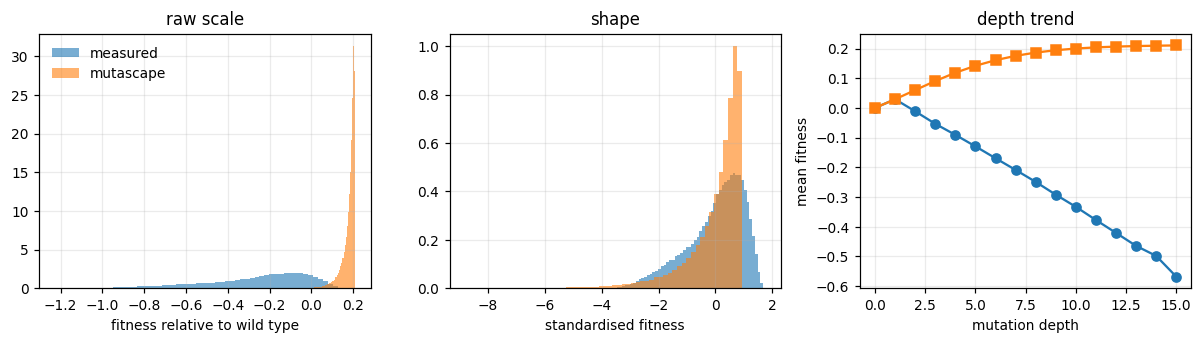

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))

axes[0].hist(m, bins=60, alpha=0.6, density=True, label="measured")
axes[0].hist(s, bins=60, alpha=0.6, density=True, label="mutascape")
axes[0].set_xlabel("fitness relative to wild type")
axes[0].set_title("raw scale")
axes[0].legend(frameon=False)

axes[1].hist((m - m.mean()) / m.std(), bins=60, alpha=0.6, density=True, label="measured")
axes[1].hist((s - s.mean()) / s.std(), bins=60, alpha=0.6, density=True, label="mutascape")
axes[1].set_xlabel("standardised fitness")
axes[1].set_title("shape")

axes[2].plot(by_depth.index, by_depth["measured"], "o-", label="measured")
axes[2].plot(by_depth.index, by_depth["mutascape"], "s-", label="mutascape")
axes[2].set_xlabel("mutation depth")
axes[2].set_ylabel("mean fitness")
axes[2].set_title("depth trend")

fig.tight_layout()

Read the depth column first. The measured landscape falls as mutations
accumulate, reaching about -0.57 at depth fifteen. The synthetic one rises then
flattens. All twenty singles are mildly beneficial. A model built from them
cannot learn that CreiLOV breaks when you stack them.

This is the limit of conditioning on singles. Section 9 repeats the measurement
on landscapes where the singles do carry the signal.

### Walsh spectrum and local optima

The Walsh spectrum splits fitness variance by interaction order. Order one is
additive. Everything above it is epistasis. Local optima count the points where
a hill-climbing search terminates.

An exact optimum count over the full cube is too slow. Both quantities are
computed on the complete binary sub-cube, with every multi-substitution
position fixed at wild type. The Walsh transform requires a proper hypercube.

In [18]:
binary_axes = [i for i, p in enumerate(cube.positions) if len(cube.alphabets[p]) == 2]
slicer = tuple(
    slice(None) if i in binary_axes else cube.alphabets[p].index(cube.wild_type[p])
    for i, p in enumerate(cube.positions)
)
sub_measured, sub_synthetic = measured[slicer], synthetic[slicer]
print(
    f"binary sub-cube: {len(binary_axes)} positions, "
    f"{np.isfinite(sub_measured).sum():,} of {sub_measured.size:,} measured"
)

rows = {}
for name, tensor in (("measured", sub_measured), ("mutascape", sub_synthetic)):
    spectrum = walsh_decompose(tensor)
    rows[name] = {
        "std": float(np.nanstd(tensor)),
        "additive share": spectrum[1],
        "epistatic share": sum(v for order, v in spectrum.items() if order >= 2),
        "pairwise share": spectrum.get(2, 0.0),
        "order 4+ share": sum(v for order, v in spectrum.items() if order >= 4),
        "local optima": local_optima_from_tensor(tensor)["n_optima"],
    }
pd.DataFrame(rows).round(3)

binary sub-cube: 12 positions, 3,995 of 4,096 measured


,measured,mutascape
std,0.082,0.034
additive share,0.757,0.814
epistatic share,0.243,0.186
pairwise share,0.075,0.166
order 4+ share,0.145,0.001
local optima,47.000,1.000


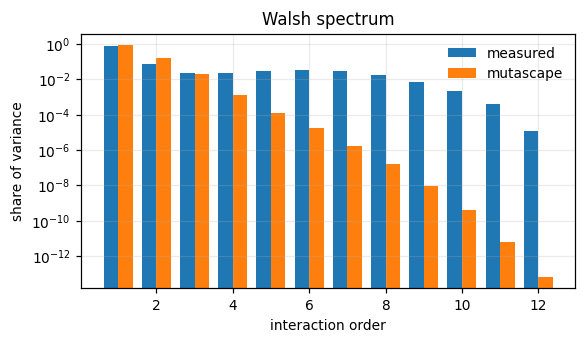

In [19]:
fig, ax = plt.subplots(figsize=(5.4, 3.2))
width, orders = 0.38, range(1, len(binary_axes) + 1)
for offset, (name, tensor) in zip(
    (-width / 2, width / 2), (("measured", sub_measured), ("mutascape", sub_synthetic))
):
    spectrum = walsh_decompose(tensor)
    ax.bar([o + offset for o in orders], [spectrum.get(o, 0.0) for o in orders], width, label=name)
ax.set_yscale("log")
ax.set_xlabel("interaction order")
ax.set_ylabel("share of variance")
ax.set_title("Walsh spectrum")
ax.legend(frameon=False)
fig.tight_layout()

## 7. Classifier two-sample test

A classifier is trained to separate measured variants from synthetic ones on
shared features. AUC near 0.5 indicates the two sets are hard to distinguish.
AUC near 1.0 indicates they are separable.

Mutascape does not claim its raw fitness distribution matches an assay.

In [20]:
test = split.test.sample(min(4000, len(split.test)), random_state=SEED)
generated = oracle.evaluate_batch(test.mutations.tolist()) + wild_type_fitness

real_features = completion_fidelity_features(split.train, test).to_numpy()
fake_features = completion_fidelity_features(split.train, test, generated).to_numpy()
groups = np.arange(len(test))

for classifier in ("logistic", "histogram"):
    result = classifier_two_sample_test(
        real_features,
        fake_features,
        real_groups=groups,
        synthetic_groups=groups,
        classifier=classifier,
        n_permutations=0,
        seed=SEED,
    )
    print(
        f"{classifier:>10}  AUC {result.auc:.3f} +/- {result.auc_std:.3f}   "
        f"accuracy {result.accuracy:.3f}"
    )

  logistic  AUC 1.000 +/- 0.000   accuracy 0.997


 histogram  AUC 1.000 +/- 0.000   accuracy 0.998


## 8. Does the method ranking transfer?

The purpose of a synthetic landscape is to rank search methods. Twelve
budget-matched methods are evaluated on the measured landscape, then on
synthetic landscapes. The question is whether the ranking is preserved.

Kendall tau quantifies this over the twelve methods. Tau of 1.0 means every
ordered pair agrees. Tau of 0.0 means the synthetic ranking is uninformative
about the measured one.

Additive, NK and Potts arms are the alternatives a benchmark would otherwise
use.

In [21]:
space = SearchSpace.from_cube(cube, finite)
features = make_features(space)
print(f"search space: {space.size:,} genotypes over {space.n_sites} sites\n")

arms = {
    "measured": measured,
    "mutascape": synthetic,
    "mutascape seed 2": dms_pairwise_readout_tensor(
        cube, generator, coupling=COUPLING, seed=SEED + 1
    ),
    "additive": additive_tensor(split.train, cube),
    "nk k=2": nk_tensor(cube, k=2, seed=SEED),
    "potts": potts_tensor(cube, split.train, coupling=0.25, seed=SEED),
}

records = []
for arm, tensor in arms.items():
    values = space.arm_values(tensor)
    start = time.perf_counter()
    for method in METHODS:
        for trial in range(TRIALS):
            records.append(
                {
                    "arm": arm,
                    "method": method,
                    "best": run_method(
                        method, space, values, features, budget=BUDGET, seed=SEED + 137 * trial
                    ),
                }
            )
    print(f"{arm:<18} {time.perf_counter() - start:5.1f}s")

scores = pd.DataFrame(records).groupby(["arm", "method"]).best.mean().unstack("arm")[list(arms)]
scores.round(4)

search space: 165,428 genotypes over 15 sites



measured             5.1s


mutascape            4.0s


mutascape seed 2     3.9s


additive             5.7s


nk k=2               5.8s


potts                5.8s


arm,measured,mutascape,mutascape seed 2,additive,nk k=2,potts
method,,,,,,
adalead,0.1514,0.2112,0.2111,0.2346,2.4797,0.9518
annealing,0.1276,0.2103,0.2098,0.2118,2.3871,0.8477
forest_greedy,0.1541,0.2113,0.2112,0.2301,2.2711,0.9104
forest_thompson,0.1213,0.2109,0.2106,0.2057,1.7029,0.8493
genetic,0.1104,0.2108,0.2108,0.1883,1.8696,0.8084
gp_ei,0.1555,0.2112,0.2112,0.2256,2.2745,0.8960
gp_ucb,0.1492,0.2112,0.2112,0.2279,2.2745,0.9131
greedy,0.1648,0.2092,0.2065,0.1846,2.2015,0.5946
mlp_ucb,0.1586,0.2112,0.2111,0.2332,2.2504,0.9332


In [22]:
transfer = pd.DataFrame(
    [
        {
            "arm": arm,
            "kendall tau": kendalltau(scores["measured"], scores[arm]).statistic,
            "pairs preserved": (kendalltau(scores["measured"], scores[arm]).statistic + 1) / 2,
            "top method": scores[arm].idxmax(),
        }
        for arm in scores.columns
        if arm != "measured"
    ]
).set_index("arm")
print(f"top method on the measured landscape: {scores['measured'].idxmax()}")
transfer.sort_values("kendall tau", ascending=False).round(3)

top method on the measured landscape: greedy


,kendall tau,pairs preserved,top method
arm,,,
additive,0.382,0.691,adalead
potts,0.303,0.652,adalead
mutascape,0.242,0.621,forest_greedy
mutascape seed 2,0.168,0.584,forest_greedy
nk k=2,0.107,0.553,adalead


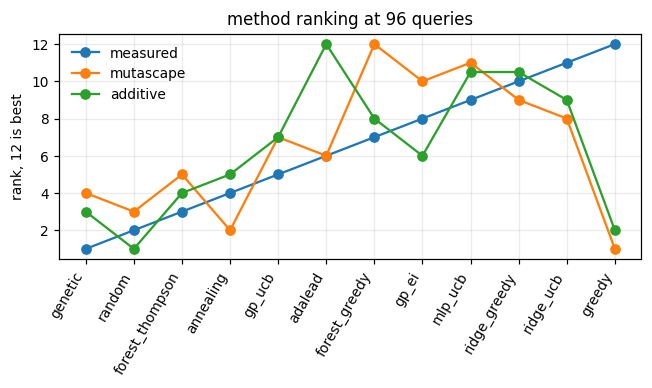

In [23]:
fig, ax = plt.subplots(figsize=(6.0, 3.6))
order = scores["measured"].sort_values().index
for arm in ("measured", "mutascape", "additive"):
    ax.plot(range(len(order)), scores.loc[order, arm].rank().to_numpy(), "o-", label=arm)
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=60, ha="right")
ax.set_ylabel("rank, 12 is best")
ax.set_title(f"method ranking at {BUDGET} queries")
ax.legend(frameon=False)
fig.tight_layout()

Compare the spread within each column of the score table above. On the measured
landscape the twelve methods separate. On the mutascape arm most return almost
the same value. The synthetic surface is single-peaked with a wide plateau near
the top. Any method that improves at all reaches it. Tau is computed over a
near-tie. This makes it low and unstable across seeds.

CreiLOV is the hard case. Run section 9 before drawing a conclusion from this
number.

## 9. The same measurement on other landscapes

One landscape is one data point. The same loop over several measured landscapes
shows the spread.

In [24]:
SWEEP = [
    "CreiLOV_fluorescence",
    "GB1_binding",
    "eqFP611_red",
    "HIV1_activity",
    "TrpB3A",
    "ParD3",
    "DHFR",
    "T7",
]
SWEEP_TRIALS = 3


def build_generator(landscape):
    """Condition a generator on one landscape's own wild type and singles."""
    parts = mutation_order_split(landscape.variants, max_train_depth=1)
    seq = landscape.wild_type_sequence
    wt = float(parts.train.loc[parts.train.depth == 0, "fitness"].iloc[0])
    frame = pd.DataFrame(
        [
            {"position": p, "wildtype": seq[p - 1], "mutant": a, "fitness": f - wt}
            for mutations, f in parts.train.loc[
                parts.train.depth == 1, ["mutations", "fitness"]
            ].itertuples(index=False, name=None)
            for p, a in mutations.items()
        ]
    )
    return from_dms(frame, wt_sequence=seq), parts


def transfer_tau(name, *, budget=BUDGET, trials=SWEEP_TRIALS):
    """Kendall tau between measured and synthetic method rankings."""
    landscape = LANDSCAPES[name]
    posterior, parts = build_generator(landscape)
    spec = supported_cube(landscape, parts.train)
    real, cover = measured_tensor(landscape, spec)
    keep = np.isfinite(real)
    grid = SearchSpace.from_cube(spec, keep)
    feats = make_features(grid)
    tensors = {
        "measured": real,
        "mutascape": dms_pairwise_readout_tensor(spec, posterior, coupling=COUPLING, seed=SEED),
        "additive": additive_tensor(parts.train, spec),
    }
    means = {
        arm: pd.Series(
            {
                method: float(
                    np.mean(
                        [
                            run_method(
                                method,
                                grid,
                                grid.arm_values(tensor),
                                feats,
                                budget=budget,
                                seed=SEED + 137 * t,
                            )
                            for t in range(trials)
                        ]
                    )
                )
                for method in METHODS
            }
        )
        for arm, tensor in tensors.items()
    }
    return {
        "landscape": name,
        "protein": landscape.protein,
        "genotypes": int(keep.sum()),
        "coverage": cover,
        "mutascape": kendalltau(means["measured"], means["mutascape"]).statistic,
        "additive": kendalltau(means["measured"], means["additive"]).statistic,
    }


sweep = []
for name in SWEEP:
    if name not in LANDSCAPES:
        print(f"skipped {name}, not on disk")
        continue
    start = time.perf_counter()
    sweep.append(transfer_tau(name))
    print(f"{name:<24} {time.perf_counter() - start:5.1f}s")
sweep = pd.DataFrame(sweep).set_index("landscape")
sweep.round(3)

CreiLOV_fluorescence      10.9s


GB1_binding                4.9s


eqFP611_red                5.9s


HIV1_activity              3.3s


TrpB3A                     2.2s


ParD3                      2.1s


DHFR                       2.3s


T7                         1.8s


,protein,genotypes,coverage,mutascape,additive
landscape,,,,,
CreiLOV_fluorescence,CreiLOV,165428,0.898,0.212,0.412
GB1_binding,GB1,149361,0.934,0.813,0.598
eqFP611_red,eqFP611,8192,1.000,0.154,0.692
HIV1_activity,HIV-1,1175,0.255,0.757,0.757
TrpB3A,TrpB,7574,0.997,0.689,0.178
ParD3,ParD,7882,0.985,0.000,0.032
DHFR,DHFR,8000,1.000,0.403,0.374
T7,T7,2838,0.889,0.283,0.283


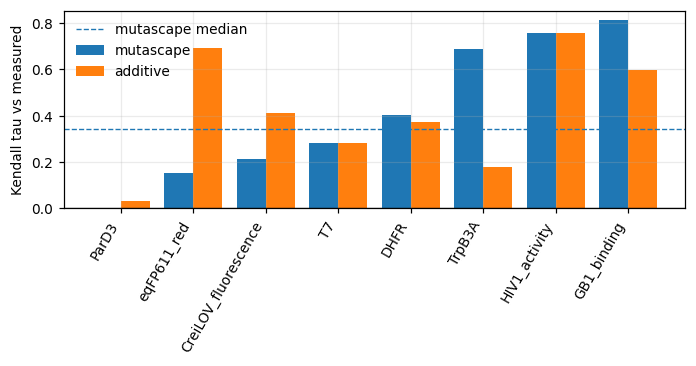

In [25]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
order = sweep.sort_values("mutascape").index
x = np.arange(len(order))
ax.bar(x - 0.2, sweep.loc[order, "mutascape"], 0.4, label="mutascape")
ax.bar(x + 0.2, sweep.loc[order, "additive"], 0.4, label="additive")
ax.axhline(0, color="k", lw=0.8)
ax.axhline(sweep["mutascape"].median(), ls="--", lw=0.9, color="C0", label="mutascape median")
ax.set_xticks(x)
ax.set_xticklabels(order, rotation=60, ha="right")
ax.set_ylabel("Kendall tau vs measured")
ax.legend(frameon=False)
fig.tight_layout()

## 10. Benchmark your own method

`Campaign` provides a method with a budget, a candidate pool and a measurement
channel. The oracle is not exposed. A method obtains fitness only through
`measure`. Each new variant deducts from the budget. Define a function that spends the
budget. `run_campaign` scores it against the pool optimum. The same function
runs unchanged on any oracle in this notebook.

In [26]:
def uniform(campaign):
    """Spend the whole budget on random plates."""
    while campaign.remaining:
        take = min(campaign.batch_size, campaign.remaining)
        campaign.measure(campaign.sample(take, seed=campaign.round))


def greedy_neighbourhood(campaign):
    """Random opening plate, then plates sharing mutations with the incumbent."""
    campaign.measure(campaign.sample(campaign.batch_size, seed=0))
    while campaign.remaining:
        seen = campaign.observed
        incumbent = set(seen.loc[seen.fitness.idxmax(), "variant"].split("+"))
        pool = campaign.sample(min(3000, campaign.remaining * 20), seed=campaign.round)
        ranked = sorted(pool, key=lambda m: -len(incumbent & set(m.label.split("+"))))
        campaign.measure(ranked[: min(campaign.batch_size, campaign.remaining)])

A campaign accepts any object exposing `domain`, `evaluate` and
`evaluate_batch`. The measured landscape satisfies that interface and runs the
same method code.

In [27]:
class MeasuredOracle:
    """The measured landscape, answering the same calls the synthetic one does."""

    def __init__(self, variants, domain, wild_type_fitness):
        self.domain = domain
        self._values = {
            tuple(sorted(mutations.items())): float(fitness) - wild_type_fitness
            for mutations, fitness in variants[["mutations", "fitness"]].itertuples(
                index=False, name=None
            )
        }

    def evaluate(self, mutations):
        key = tuple(sorted(self.domain.parse(mutations).items()))
        return self._values.get(key, float("nan"))

    def evaluate_batch(self, variants):
        return np.asarray([self.evaluate(variant) for variant in variants], dtype=float)


truth = MeasuredOracle(dataset.variants, oracle.domain, wild_type_fitness)

# Candidates both oracles can answer, so the two runs are comparable.
pool = (
    dataset.variants.loc[dataset.variants.depth >= 2, "mutations"]
    .sample(20000, random_state=SEED)
    .tolist()
)

outcome = pd.DataFrame(
    [
        {
            "landscape": arm,
            "method": name,
            "budget": budget,
            **run_campaign(fn, target, pool, budget=budget, seed=SEED).to_dict(),
        }
        for budget in (96, 384)
        for arm, target in (("measured", truth), ("mutascape", oracle))
        for name, fn in (("uniform", uniform), ("greedy neighbourhood", greedy_neighbourhood))
    ]
).set_index(["budget", "landscape", "method"])
outcome[["best_found", "optimum", "simple_regret"]].round(4)

best_found  optimum  simple_regret
budget landscape method                                                  
96     measured  uniform                   0.0623   0.1648         0.0788
                 greedy neighbourhood      0.0623   0.1648         0.0788
       mutascape uniform                   0.2105   0.2113         0.0025
                 greedy neighbourhood      0.2105   0.2113         0.0025
384    measured  uniform                   0.1148   0.1648         0.0384
                 greedy neighbourhood      0.0960   0.1648         0.0529
       mutascape uniform                   0.2111   0.2113         0.0004
                 greedy neighbourhood      0.2112   0.2113         0.0004

Regret is far lower on the synthetic landscape than on the measured one at the
same budget. The synthetic surface is the easier problem. Note this before
reporting an absolute success rate from it.

Assay noise changes the score. `result` reads the true fitness of the selected
variant, not the noisy read used to select it.

In [28]:
noisy = pd.DataFrame(
    [
        {
            "method": name,
            "noise": level,
            **run_campaign(fn, oracle, pool, budget=384, seed=SEED, noise=level).to_dict(),
        }
        for level in (0.0, 0.25, 0.5)
        for name, fn in (("uniform", uniform), ("greedy neighbourhood", greedy_neighbourhood))
    ]
).set_index(["method", "noise"])
noisy[["best_found", "best_observed", "simple_regret"]].round(4)

,,best_found,best_observed,simple_regret
method,noise,,,
uniform,0.00,0.2111,0.2111,0.0004
greedy neighbourhood,0.00,0.2112,0.2112,0.0004
uniform,0.25,0.2021,0.2256,0.0298
greedy neighbourhood,0.25,0.2084,0.2317,0.0092
uniform,0.50,0.2021,0.2490,0.0298
greedy neighbourhood,0.50,0.2084,0.2549,0.0092


## 11. Change protein

Set `TARGET` in cell 1 to another name from the list. Run the notebook again.
Nothing below that cell mentions CreiLOV except the optional whole-protein
section. That section skips itself.

For a protein outside the corpora, skip the split and pass your own
measurements. `from_dms` takes a path or a frame with either
`position, wildtype, mutant, fitness` or `variant, fitness` columns.

```python
oracle = from_dms("my_protein.csv", fasta="my_protein.fasta").draw(seed=0)
oracle["A29H+R60D"]
```

Fitness must be relative to wild type. For a scan with gaps,
`from_dms(..., complete="esm2")` calibrates masked ESM2 scores on the singles
you did measure and fills the rest. Every measurement stays exact.

## Summary

- The oracle is exact where measurements exist. It is evaluated lazily
  elsewhere. A benchmark can span depths no assay covers.
- A manifest plus a seed reproduce a landscape exactly. Both fail if the source
  data changed.
- Raw fitness distributions do not match an assay. The classifier test confirms
  this. Do not use mutascape as a fitness predictor. Do not report an absolute
  success rate from a synthetic landscape.
- Method rankings are often preserved under substitution. That is the claim the
  benchmark rests on. Section 9 quantifies the variation, from strong transfer
  on GB1 to none on ParD3.
- CreiLOV is a hard case, not a showcase. Twenty singles do not determine that
  the protein loses function when they are combined.